In [11]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(4, activation='softmax'))

model.summary()


/venv/main/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 173056)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,075,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,132,228 (42.47 MB)

 Trainable params: 11,132,228 (42.47 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(optimizer='adam',
            loss="categorical_crossentropy",
            metrics=['accuracy'])


In [13]:
from sklearn.utils.class_weight import compute_class_weight

w = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(w))
print(class_weight)

{0: np.float64(1.0830486763450042), 1: np.float64(1.067550505050505), 2: np.float64(0.8776816608996539), 3: np.float64(0.9994089834515366)}


In [14]:
import time

callbacks = [
    tf.keras.callbacks.ModelCheckpoint("cnn_best.keras", monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.BackupAndRestore("backup_cnn"),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=30,
                    class_weight=class_weight, callbacks=callbacks)

train_time = time.time() - start
print(f"Training time: {train_time:.0f}s")

Epoch 1/30


2026-10-28 00:58:17.167111: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 3054514176 exceeds 10% of free system memory.
I0000 00:00:1793149100.339334    1604 service.cc:152] XLA service 0x7f6f74007680 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793149100.339371    1604 service.cc:160]   StreamExecutor device (0): NVIDIA RTX A4000, Compute Capability 8.6
2026-10-28 00:58:20.532331: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793149101.531798    1604 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/159 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.3177 - loss: 3.0789  

I0000 00:00:1793149108.814974    1604 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


159/159 ━━━━━━━━━━━━━━━━━━━━ 31s 119ms/step - accuracy: 0.6156 - loss: 0.9580 - val_accuracy: 0.7812 - val_loss: 0.5743
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - accuracy: 0.7662 - loss: 0.6033 - val_accuracy: 0.7801 - val_loss: 0.5653
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.7946 - loss: 0.5373 - val_accuracy: 0.8025 - val_loss: 0.4597
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 19s 121ms/step - accuracy: 0.8074 - loss: 0.4845 - val_accuracy: 0.8359 - val_loss: 0.4364
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - accuracy: 0.8413 - loss: 0.4075 - val_accuracy: 0.8304 - val_loss: 0.4273
Epoch 6/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - accuracy: 0.8620 - loss: 0.3665 - val_accuracy: 0.8415 - val_loss: 0.4071
Epoch 7/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 103ms/step - accuracy: 0.8658 - loss: 0.3436 - val_accuracy: 0.8728 - val_loss: 0.3483
Epoch 8/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.8870 - loss: 0.2998 - val_

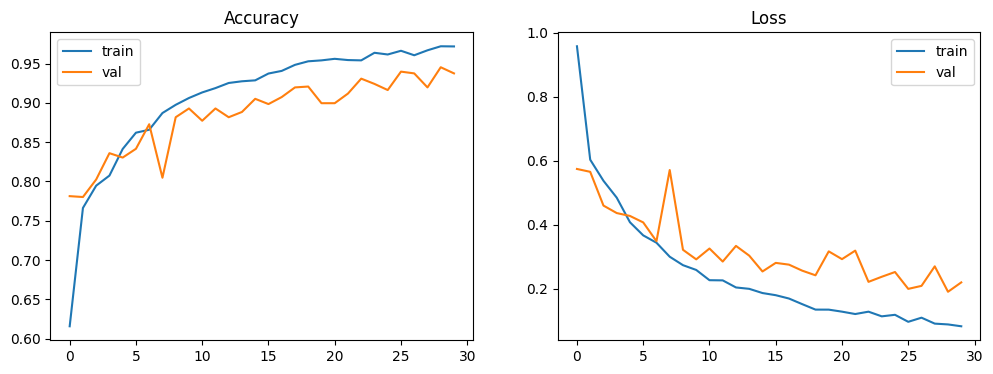

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

In [16]:
test_loss, test_acc = model.evaluate(test_ds)
print(test_loss, test_acc)

33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.9535 - loss: 0.1683
0.1683020144701004 0.9535104632377625


In [17]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASSES))
print(confusion_matrix(y_test, y_pred))

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
              precision    recall  f1-score   support

      glioma       0.93      0.94      0.93       243
  meningioma       0.92      0.92      0.92       247
     notumor       1.00      0.98      0.99       300
   pituitary       0.96      0.97      0.96       264

    accuracy                           0.95      1054
   macro avg       0.95      0.95      0.95      1054
weighted avg       0.95      0.95      0.95      1054

[[228  14   0   1]
 [ 12 228   0   7]
 [  2   2 294   2]
 [  4   5   0 255]]


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
49 wrong out of 1054


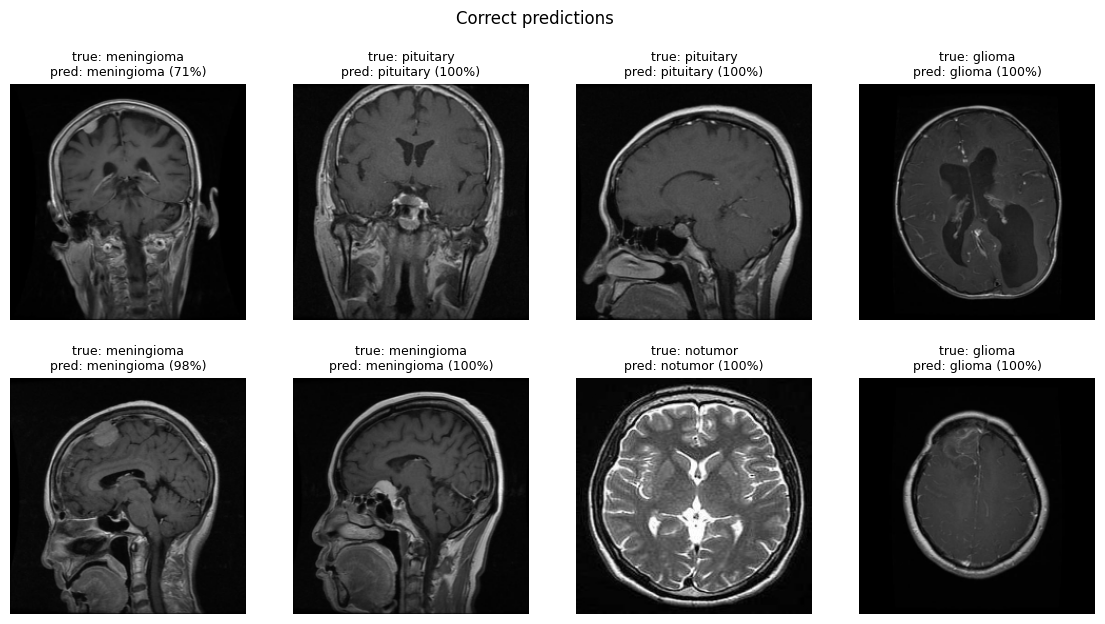

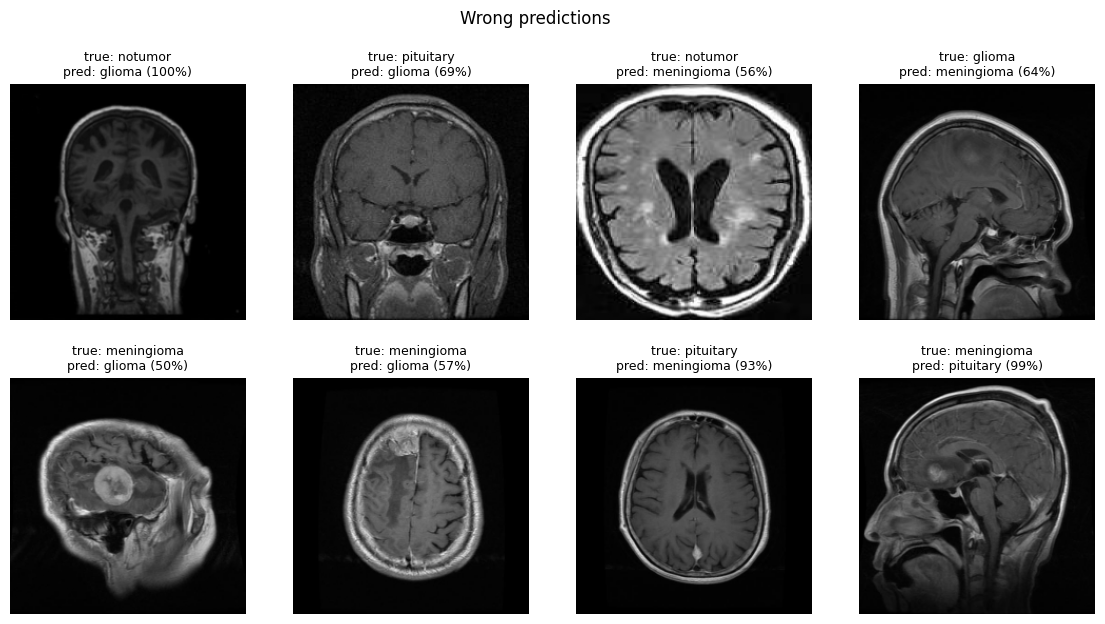

In [40]:
probs = model.predict(test_ds)
y_pred = np.argmax(probs, axis=1)

wrong = np.where(y_pred != y_test)[0]
right = np.where(y_pred == y_test)[0]
print(len(wrong), "wrong out of", len(y_test))

def show(indices, title, n=8):
    plt.figure(figsize=(14, 7))
    for k, i in enumerate(indices[:n]):
        plt.subplot(2, 4, k + 1)
        plt.imshow(X_test[i])
        plt.title(f"true: {CLASSES[y_test[i]]}\npred: {CLASSES[y_pred[i]]} ({probs[i].max():.0%})", fontsize=9)
        plt.axis("off")
    plt.suptitle(title)
    plt.show()

show(np.random.choice(right, 8, replace=False), "Correct predictions")
show(wrong, "Wrong predictions")

In [20]:
notumor = CLASSES.index("notumor")
missed = np.where((y_test != notumor) & (y_pred == notumor))[0]
print(len(missed), "tumours predicted as notumor")
show(missed, "Tumours missed (false negatives)")

0 tumours predicted as notumor


<Figure size 1400x700 with 0 Axes>